# Прогнозирование риска повторной госпитализации пациентов с диабетом

**Итоговая аттестационная работа по программе «Решение прикладных задач на Python»**  
**Обучающийся:** Николаев Даниил Сергеевич  
**Группа:** КББО-03-23

В работе используется датасет **Diabetes 130-US hospitals for years 1999–2008**. Анализ направлен на выявление факторов, связанных с повторной госпитализацией в течение 30 дней после выписки.

## Методологическое замечание

Одна строка исходного датасета соответствует **госпитализационному эпизоду**, а один пациент может встречаться несколько раз. Поэтому:

- описательная характеристика исходных данных проводится как для всех очищенных госпитализационных эпизодов, так и для уникальных пациентов;
- статистические гипотезы проверяются на выборке, содержащей **первый доступный эпизод каждого пациента**, чтобы уменьшить зависимость наблюдений;
- показатель `risk_score` является учебным аналитическим показателем и **не является клинически валидированной медицинской шкалой**.

In [1]:
from pathlib import Path
import sys
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 10,
    "grid.alpha": 0.25,
})

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.0
pandas: 3.0.3
NumPy: 2.4.6


In [2]:
# Определяем пути независимо от того, откуда запущен Notebook.
possible_paths = [
    Path.cwd() / "data" / "diabetic_data.csv",
    Path.cwd() / "03_Notebook" / "data" / "diabetic_data.csv",
    Path.cwd().parent / "03_Notebook" / "data" / "diabetic_data.csv",
]

DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Файл diabetic_data.csv не найден. Он должен лежать в папке 03_Notebook/data."
    )

BASE_DIR = DATA_PATH.parent.parent
FIGURES_DIR = BASE_DIR / "figures"
OUTPUTS_DIR = BASE_DIR / "outputs"
HYPOTHESES_DIR = OUTPUTS_DIR / "hypotheses_v2"
RISK_DIR = OUTPUTS_DIR / "risk_factors_v2"

for directory in [FIGURES_DIR, OUTPUTS_DIR, HYPOTHESES_DIR, RISK_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Датасет найден:", DATA_PATH.name)
print("Папки figures и outputs подготовлены.")

Датасет найден: diabetic_data.csv
Папки figures и outputs подготовлены.


# 1. Постановка задачи

Цель работы — проанализировать сведения о госпитализациях пациентов с диабетом, определить факторы, связанные с ранней повторной госпитализацией, проверить пять обязательных статистических гипотез и подготовить данные для интерактивного приложения на Flet.

Основные задачи:

1. загрузить и изучить исходный датасет;
2. обработать пропуски и некорректные значения;
3. преобразовать возрастные интервалы и создать новые признаки;
4. выполнить исследовательский анализ данных;
5. проверить пять статистических гипотез;
6. выявить и ранжировать факторы риска;
7. предложить исследовательские пороги и сформулировать ограничения анализа.

In [3]:
# keep_default_na=False сохраняет строку "None" как категорию результата анализа,
# а не превращает её автоматически в NaN.
df_raw = pd.read_csv(DATA_PATH, low_memory=False, keep_default_na=False)

print("Размер исходного датасета:", df_raw.shape)
print("Количество госпитализационных эпизодов:", len(df_raw))
print("Количество уникальных patient_nbr:", df_raw["patient_nbr"].nunique())
display(df_raw.head())

Размер исходного датасета: (101766, 50)
Количество госпитализационных эпизодов: 101766
Количество уникальных patient_nbr: 71518


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
print("Типы данных и заполненность столбцов:")
df_raw.info()

Типы данных и заполненность столбцов:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int6

In [5]:
question_marks = pd.Series(0, index=df_raw.columns, dtype="int64")
object_columns = df_raw.select_dtypes(include="object").columns
question_marks.loc[object_columns] = df_raw[object_columns].eq("?").sum()

missing_initial = pd.DataFrame({
    "Столбец": df_raw.columns,
    "Значений '?'": question_marks.values,
    "Пустых строк": [df_raw[column].eq("").sum() if df_raw[column].dtype == "object" else 0 for column in df_raw.columns],
})
missing_initial["Всего проблемных"] = missing_initial["Значений '?'"] + missing_initial["Пустых строк"]
missing_initial = missing_initial.sort_values("Всего проблемных", ascending=False)

display(missing_initial.head(15))
missing_initial.to_csv(OUTPUTS_DIR / "missing_values_initial_v2.csv", index=False, encoding="utf-8-sig")

,Столбец,Значений '?',Пустых строк,Всего проблемных
5,weight,98569,0,98569
11,medical_specialty,49949,0,49949
10,payer_code,40256,0,40256
2,race,2273,0,2273
20,diag_3,1423,0,1423
19,diag_2,358,0,358
18,diag_1,21,0,21
6,admission_type_id,0,0,0
1,patient_nbr,0,0,0
0,encounter_id,0,0,0


# 2. Описание датасета

Исходный набор содержит сведения о госпитализациях в 130 медицинских учреждениях США за 1999–2008 годы. В нём представлены демографические данные, сведения о госпитализации, диагнозах, лабораторных исследованиях, назначенных лекарствах и последующей повторной госпитализации.

Целевая переменная `readmitted` принимает значения:

- `<30` — повторная госпитализация произошла менее чем через 30 дней;
- `>30` — повторная госпитализация произошла позднее 30 дней;
- `NO` — повторная госпитализация не зарегистрирована.

In [6]:
data_dictionary = pd.DataFrame([
    ["patient_nbr", "Идентификатор пациента", "Используется для выделения уникальных пациентов"],
    ["race", "Расовая группа", "Демографический фактор"],
    ["gender", "Пол", "Демографический фактор"],
    ["age", "Возрастной интервал", "Преобразуется в среднее значение интервала"],
    ["time_in_hospital", "Длительность пребывания", "Характеристика госпитализации"],
    ["number_inpatient", "Предыдущие стационарные обращения", "Число стационарных обращений за предшествующий год"],
    ["number_emergency", "Экстренные обращения", "Число экстренных обращений за предшествующий год"],
    ["number_diagnoses", "Количество диагнозов", "Прокси-показатель диагностической нагрузки"],
    ["num_medications", "Количество назначенных лекарств", "Общая лекарственная нагрузка"],
    ["A1Cresult", "Категория результата HbA1c", "None, Norm, >7 или >8"],
    ["diag_1/diag_2/diag_3", "Коды диагнозов ICD-9", "Используются для формирования групп заболеваний"],
    ["readmitted", "Факт повторной госпитализации", "Целевая переменная"],
], columns=["Признак", "Содержание", "Использование в анализе"])

display(data_dictionary)
data_dictionary.to_csv(OUTPUTS_DIR / "data_dictionary_v2.csv", index=False, encoding="utf-8-sig")

,Признак,Содержание,Использование в анализе
0,patient_nbr,Идентификатор пациента,Используется для выделения уникальных пациентов
1,race,Расовая группа,Демографический фактор
2,gender,Пол,Демографический фактор
3,age,Возрастной интервал,Преобразуется в среднее значение интервала
4,time_in_hospital,Длительность пребывания,Характеристика госпитализации
5,number_inpatient,Предыдущие стационарные обращения,Число стационарных обращений за предшествующий...
6,number_emergency,Экстренные обращения,Число экстренных обращений за предшествующий год
7,number_diagnoses,Количество диагнозов,Прокси-показатель диагностической нагрузки
8,num_medications,Количество назначенных лекарств,Общая лекарственная нагрузка
9,A1Cresult,Категория результата HbA1c,"None, Norm, >7 или >8"


# 3. Предобработка данных

В исходном файле часть пропусков записана символом `?`. На этапе предобработки они заменяются на `NaN`. Также исключаются записи с некорректным полом и эпизоды, завершившиеся смертью пациента или переводом в хоспис, поскольку для таких случаев анализ повторной госпитализации методологически некорректен.

In [7]:
df_encounters = df_raw.replace("?", np.nan).copy()

before_rows = len(df_encounters)
df_encounters = df_encounters[df_encounters["gender"] != "Unknown/Invalid"].copy()
removed_gender = before_rows - len(df_encounters)

death_or_hospice_ids = [11, 13, 14, 19, 20, 21]
before_death_filter = len(df_encounters)
df_encounters = df_encounters[
    ~df_encounters["discharge_disposition_id"].isin(death_or_hospice_ids)
].copy()
removed_death_hospice = before_death_filter - len(df_encounters)

df_encounters["readmitted_30"] = (df_encounters["readmitted"] == "<30").astype(int)

print("Удалено записей с некорректным полом:", removed_gender)
print("Удалено эпизодов смерть/хоспис:", removed_death_hospice)
print("Очищенных госпитализационных эпизодов:", len(df_encounters))
print("Уникальных пациентов после очистки:", df_encounters["patient_nbr"].nunique())
print(f"Доля readmitted <30 среди эпизодов: {df_encounters['readmitted_30'].mean() * 100:.2f}%")

Удалено записей с некорректным полом: 3
Удалено эпизодов смерть/хоспис: 2423
Очищенных госпитализационных эпизодов: 99340
Уникальных пациентов после очистки: 69987
Доля readmitted <30 среди эпизодов: 11.39%


In [8]:
# Для статистических тестов оставляем первый доступный эпизод каждого пациента.
df_patients = (
    df_encounters
    .sort_values("encounter_id")
    .drop_duplicates(subset="patient_nbr", keep="first")
    .copy()
)

raw_encounter_count = len(df_raw)
clean_encounter_count = len(df_encounters)
encounter_race_readmission = df_encounters[["race", "readmitted_30"]].copy()

print("Размер пациент-уровневой выборки:", df_patients.shape)
print("Уникальных пациентов:", df_patients["patient_nbr"].nunique())
print(f"Доля readmitted <30 на пациент-уровне: {df_patients['readmitted_30'].mean() * 100:.2f}%")

# Освобождаем память: далее полный набор эпизодов не нужен.
del df_raw, df_encounters

Размер пациент-уровневой выборки: (69987, 51)
Уникальных пациентов: 69987
Доля readmitted <30 на пациент-уровне: 8.98%


In [9]:
age_mapping = {
    "[0-10)": 5,
    "[10-20)": 15,
    "[20-30)": 25,
    "[30-40)": 35,
    "[40-50)": 45,
    "[50-60)": 55,
    "[60-70)": 65,
    "[70-80)": 75,
    "[80-90)": 85,
    "[90-100)": 95,
}

for frame in [df_patients]:
    frame["age_mid"] = frame["age"].map(age_mapping)
    frame["age_group"] = pd.cut(
        frame["age_mid"],
        bins=[0, 30, 50, 70, 100],
        labels=["до 30 лет", "30–50 лет", "50–70 лет", "старше 70 лет"],
        include_lowest=True,
    )
    # Интервал [70-80) аппроксимируется серединой 75 лет.
    frame["older_70"] = (frame["age_mid"] > 70).astype(int)

display(df_patients[["age", "age_mid", "age_group", "older_70"]].head())

,age,age_mid,age_group,older_70
8,[80-90),85,старше 70 лет,1
9,[90-100),95,старше 70 лет,1
4,[40-50),45,30–50 лет,0
10,[40-50),45,30–50 лет,0
5,[50-60),55,50–70 лет,0


In [10]:
a1c_mapping = {"Norm": 0, ">7": 1, ">8": 2}

for frame in [df_patients]:
    frame["a1c_measured"] = frame["A1Cresult"].isin(["Norm", ">7", ">8"]).astype(int)
    frame["a1c_high_8"] = (frame["A1Cresult"] == ">8").astype(int)
    frame["a1c_level"] = frame["A1Cresult"].map(a1c_mapping)
    frame["glucose_high"] = frame["max_glu_serum"].isin([">200", ">300"]).astype(int)

print("Распределение A1Cresult:")
display(df_patients["A1Cresult"].value_counts(dropna=False).rename_axis("A1Cresult").to_frame("Количество"))
print(f"HbA1c измерен у {df_patients['a1c_measured'].mean() * 100:.2f}% уникальных пациентов.")

Распределение A1Cresult:


,Количество
A1Cresult,
None,57141
>8,6239
Norm,3741
>7,2866


HbA1c измерен у 18.35% уникальных пациентов.


In [11]:
def icd9_category(value):
    if pd.isna(value) or value == "":
        return "Не указан"

    text = str(value).strip()
    if text.startswith("V"):
        return "Дополнительные факторы"
    if text.startswith("E"):
        return "Внешние причины"

    try:
        number = float(text)
    except ValueError:
        return "Другие"

    if 250 <= number < 251:
        return "Диабет"
    if 390 <= number < 460 or number == 785:
        return "Сердечно-сосудистые"
    if 460 <= number < 520 or number == 786:
        return "Респираторные"
    if 520 <= number < 580 or number == 787:
        return "Пищеварительная система"
    if 580 <= number < 630 or number == 788:
        return "Мочеполовая система"
    if 140 <= number < 240:
        return "Новообразования"
    if 710 <= number < 740:
        return "Опорно-двигательная система"
    if 800 <= number < 1000:
        return "Травмы"
    return "Другие"

for frame in [df_patients]:
    for diagnosis_column in ["diag_1", "diag_2", "diag_3"]:
        frame[f"{diagnosis_column}_category"] = frame[diagnosis_column].apply(icd9_category)

    frame["cardiovascular_disease"] = (
        frame[["diag_1_category", "diag_2_category", "diag_3_category"]]
        .eq("Сердечно-сосудистые")
        .any(axis=1)
        .astype(int)
    )
    frame["diagnosis_count"] = frame["number_diagnoses"]
    frame["diagnoses_3plus"] = (frame["number_diagnoses"] >= 3).astype(int)
    frame["diagnosis_group"] = pd.cut(
        frame["number_diagnoses"],
        bins=[-1, 2, 5, np.inf],
        labels=["0–2", "3–5", "6 и более"],
    )

print("Категории основного диагноза:")
display(df_patients["diag_1_category"].value_counts().to_frame("Количество"))

Категории основного диагноза:


,Количество
diag_1_category,
Сердечно-сосудистые,21389
Другие,11205
Респираторные,9491
Пищеварительная система,6488
Диабет,5748
Травмы,4694
Опорно-двигательная система,4064
Мочеполовая система,3441
Новообразования,2538


In [12]:
medication_columns = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "examide",
    "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
]
medication_columns = [column for column in medication_columns if column in df_patients.columns]

medication_threshold = float(df_patients["num_medications"].median())

for frame in [df_patients]:
    frame["medications_count"] = frame["num_medications"]
    frame["active_diabetes_medications_count"] = frame[medication_columns].ne("No").sum(axis=1)
    frame["insulin_used"] = (frame["insulin"] != "No").astype(int)
    frame["treatment_changed"] = (frame["change"] == "Ch").astype(int)
    frame["many_medications"] = (frame["num_medications"] >= medication_threshold).astype(int)
    frame["had_previous_inpatient"] = (frame["number_inpatient"] > 0).astype(int)
    frame["had_emergency_visits"] = (frame["number_emergency"] > 0).astype(int)
    frame["had_outpatient_visits"] = (frame["number_outpatient"] > 0).astype(int)

print("Медианный порог лекарственной нагрузки:", medication_threshold)
display(df_patients[[
    "num_medications", "medications_count", "active_diabetes_medications_count",
    "insulin_used", "treatment_changed"
]].head())

Медианный порог лекарственной нагрузки: 14.0


,num_medications,medications_count,active_diabetes_medications_count,insulin_used,treatment_changed
8,28,28,2,1,1
9,18,18,2,1,1
4,8,8,2,1,1
10,17,17,1,1,0
5,16,16,1,1,0


In [13]:
# Учебный индикатор тяжёлого течения диабета.
# Он требует HbA1c > 8% и хотя бы одного дополнительного признака сложности случая.
for frame in [df_patients]:
    frame["severe_diabetes"] = (
        (frame["a1c_high_8"] == 1)
        & (
            (frame["cardiovascular_disease"] == 1)
            | (frame["number_diagnoses"] >= 6)
            | (frame["insulin_used"] == 1)
        )
    ).astype(int)

    # HbA1c > 8% не включается в risk_score, поскольку обязательная гипотеза
    # о повышении риска этим фактором не подтверждается на пациент-уровневой выборке.
    risk_features = [
        "diagnoses_3plus",
        "older_70",
        "had_previous_inpatient",
        "had_emergency_visits",
        "many_medications",
        "insulin_used",
    ]
    frame["risk_score"] = frame[risk_features].sum(axis=1)
    frame["risk_group"] = pd.cut(
        frame["risk_score"],
        bins=[-1, 1, 3, len(risk_features)],
        labels=["низкий риск", "средний риск", "высокий риск"],
    )

print("Распределение severe_diabetes:")
display(df_patients["severe_diabetes"].value_counts().rename_axis("Значение").to_frame("Количество"))
print("Распределение учебных групп риска:")
display(df_patients["risk_group"].value_counts().to_frame("Количество"))

Распределение severe_diabetes:


,Количество
Значение,
0,63983
1,6004


Распределение учебных групп риска:


,Количество
risk_group,
средний риск,45945
высокий риск,14742
низкий риск,9300


In [14]:
# Кодирование категориальных признаков для возможного моделирования.
encoding_source = df_patients[[
    "gender", "race", "diag_1_category", "age_group"
]].astype("object").fillna("Unknown")

encoded_categories = pd.get_dummies(
    encoding_source,
    columns=["gender", "race", "diag_1_category", "age_group"],
    dtype=int,
)

encoded_numeric = df_patients[[
    "age_mid", "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses", "a1c_level", "readmitted_30"
]].reset_index(drop=True)

encoded_patients = pd.concat(
    [encoded_numeric, encoded_categories.reset_index(drop=True)],
    axis=1,
)

print("Размер закодированной аналитической таблицы:", encoded_patients.shape)
display(encoded_patients.head())

Размер закодированной аналитической таблицы: (69987, 35)


,age_mid,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,a1c_level,readmitted_30,gender_Female,gender_Male,race_AfricanAmerican,race_Asian,race_Caucasian,race_Hispanic,race_Other,race_Unknown,diag_1_category_Внешние причины,diag_1_category_Диабет,diag_1_category_Дополнительные факторы,diag_1_category_Другие,diag_1_category_Мочеполовая система,diag_1_category_Не указан,diag_1_category_Новообразования,diag_1_category_Опорно-двигательная система,diag_1_category_Пищеварительная система,diag_1_category_Респираторные,diag_1_category_Сердечно-сосудистые,diag_1_category_Травмы,age_group_30–50 лет,age_group_50–70 лет,age_group_до 30 лет,age_group_старше 70 лет
0,85,13,68,2,28,0,0,0,8,NaN,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
1,95,12,33,3,18,0,0,0,8,NaN,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,45,1,51,0,8,0,0,0,5,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
3,45,9,47,2,17,0,0,0,9,NaN,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4,55,3,31,6,16,0,0,0,9,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0


In [15]:
# Сохраняем основную пациент-уровневую таблицу и закодированные признаки в сжатом виде.
df_patients.to_csv(
    OUTPUTS_DIR / "prepared_patients_first_encounter_v2.csv.gz",
    index=False,
    compression="gzip",
    encoding="utf-8-sig",
)
encoded_patients.to_csv(
    OUTPUTS_DIR / "encoded_patients_v2.csv.gz",
    index=False,
    compression="gzip",
    encoding="utf-8-sig",
)

print("Подготовленные таблицы сохранены в папку outputs в формате CSV.GZ.")

Подготовленные таблицы сохранены в папку outputs в формате CSV.GZ.


# 4. Исследовательский анализ данных (EDA)

Для демографических характеристик и статистического анализа используется пациент-уровневая выборка. Это позволяет избежать многократного учёта одного пациента. Визуализации сохраняются в папку `figures`.

In [16]:
def save_and_show(filename):
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Сохранён график:", filename)

AGE_ORDER = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
    "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"
]

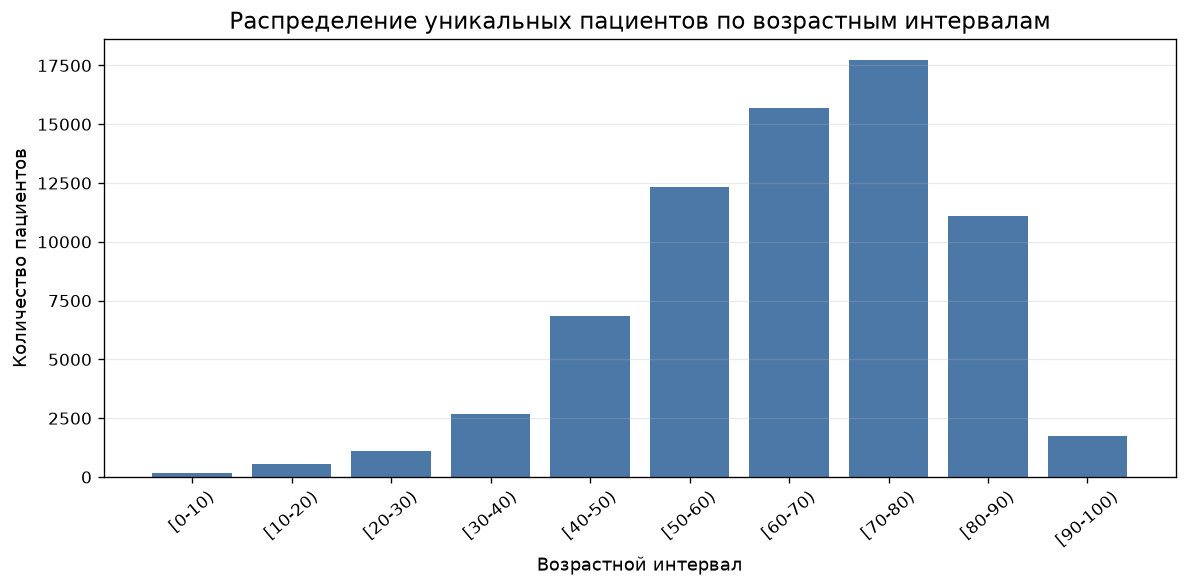

Сохранён график: 01_age_distribution_v2.png


In [17]:
age_counts = df_patients["age"].value_counts().reindex(AGE_ORDER).fillna(0)

plt.figure(figsize=(10, 5))
plt.bar(age_counts.index, age_counts.values, color="#4C78A8")
plt.title("Распределение уникальных пациентов по возрастным интервалам")
plt.xlabel("Возрастной интервал")
plt.ylabel("Количество пациентов")
plt.xticks(rotation=40)
plt.grid(axis="y")
save_and_show("01_age_distribution_v2.png")

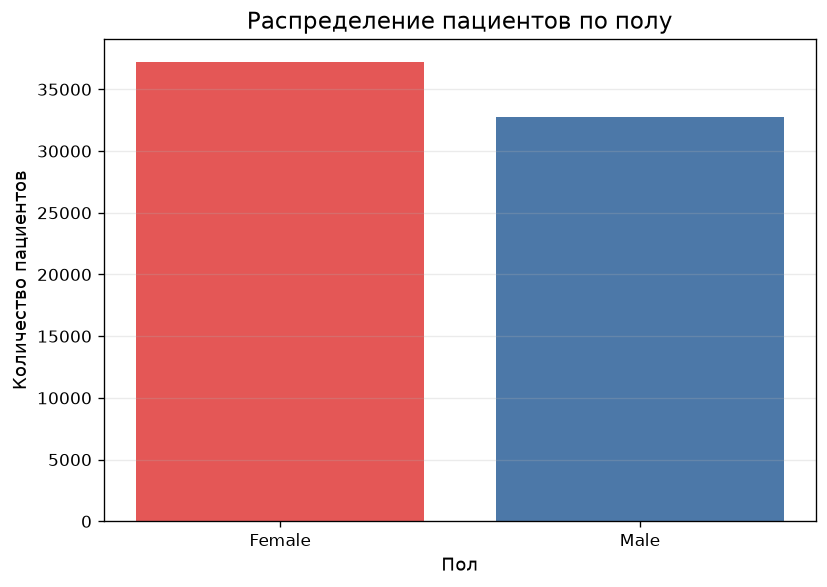

Сохранён график: 02_gender_distribution_v2.png


In [18]:
gender_counts = df_patients["gender"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(gender_counts.index, gender_counts.values, color=["#E45756", "#4C78A8"])
plt.title("Распределение пациентов по полу")
plt.xlabel("Пол")
plt.ylabel("Количество пациентов")
plt.grid(axis="y")
save_and_show("02_gender_distribution_v2.png")

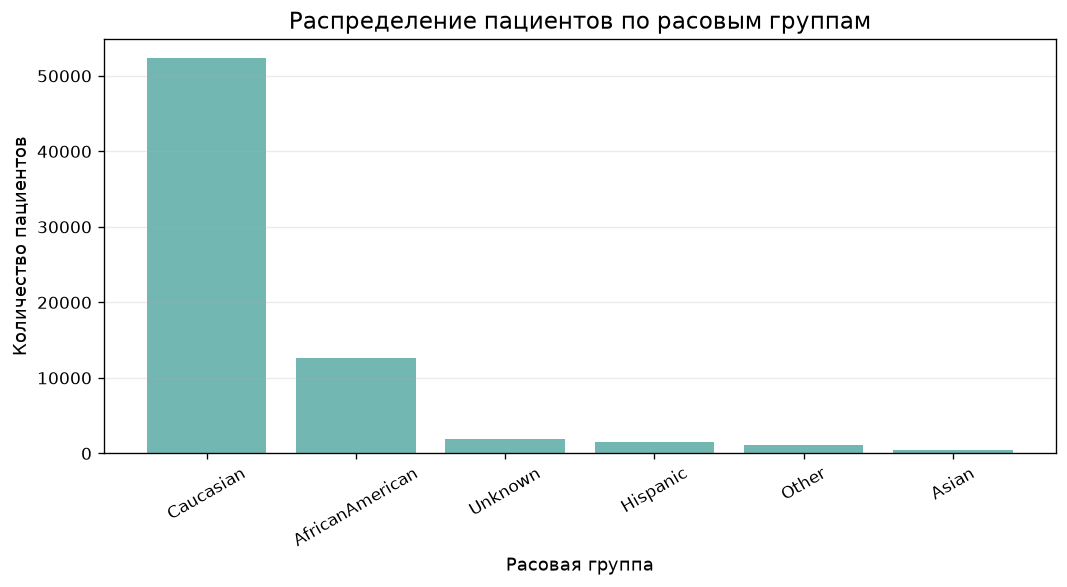

Сохранён график: 03_race_distribution_v2.png


In [19]:
race_counts = df_patients["race"].fillna("Unknown").value_counts()

plt.figure(figsize=(9, 5))
plt.bar(race_counts.index, race_counts.values, color="#72B7B2")
plt.title("Распределение пациентов по расовым группам")
plt.xlabel("Расовая группа")
plt.ylabel("Количество пациентов")
plt.xticks(rotation=30)
plt.grid(axis="y")
save_and_show("03_race_distribution_v2.png")

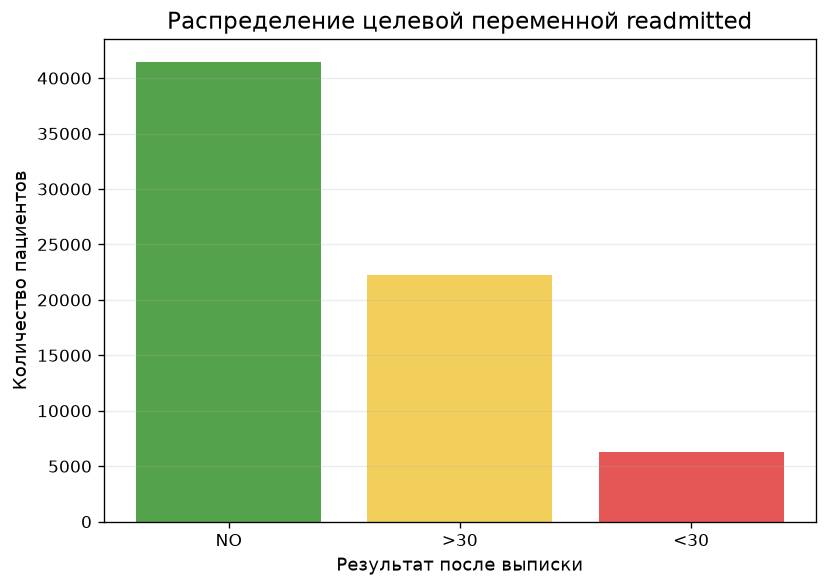

Сохранён график: 04_readmitted_distribution_v2.png


In [20]:
readmission_counts = df_patients["readmitted"].value_counts().reindex(["NO", ">30", "<30"])

plt.figure(figsize=(7, 5))
plt.bar(readmission_counts.index, readmission_counts.values, color=["#54A24B", "#F2CF5B", "#E45756"])
plt.title("Распределение целевой переменной readmitted")
plt.xlabel("Результат после выписки")
plt.ylabel("Количество пациентов")
plt.grid(axis="y")
save_and_show("04_readmitted_distribution_v2.png")

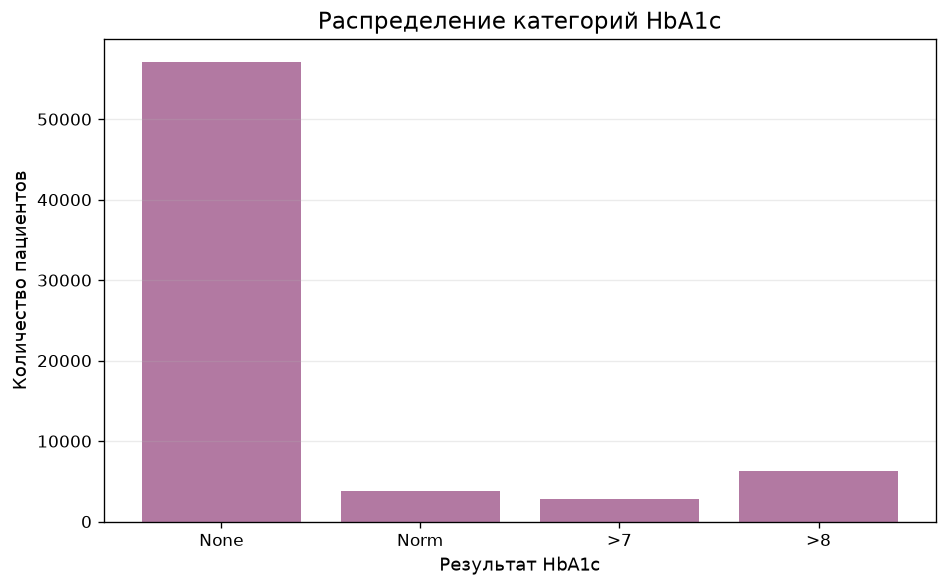

Сохранён график: 05_a1c_distribution_v2.png


In [21]:
a1c_counts = df_patients["A1Cresult"].value_counts().reindex(["None", "Norm", ">7", ">8"]).fillna(0)

plt.figure(figsize=(8, 5))
plt.bar(a1c_counts.index, a1c_counts.values, color="#B279A2")
plt.title("Распределение категорий HbA1c")
plt.xlabel("Результат HbA1c")
plt.ylabel("Количество пациентов")
plt.grid(axis="y")
save_and_show("05_a1c_distribution_v2.png")

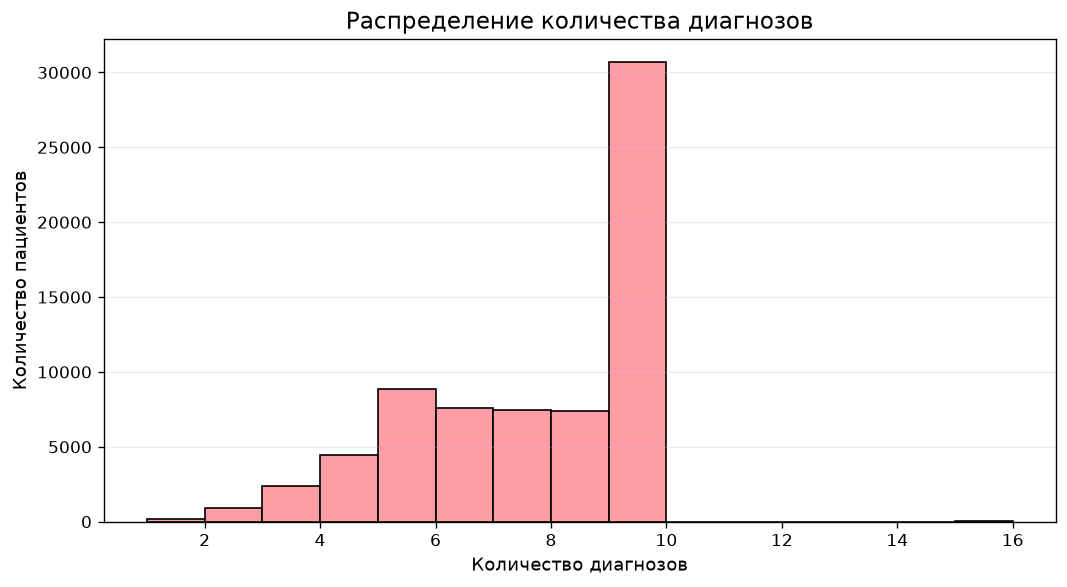

Сохранён график: 06_number_diagnoses_hist_v2.png


In [22]:
plt.figure(figsize=(9, 5))
plt.hist(df_patients["number_diagnoses"], bins=15, color="#FF9DA6", edgecolor="black")
plt.title("Распределение количества диагнозов")
plt.xlabel("Количество диагнозов")
plt.ylabel("Количество пациентов")
plt.grid(axis="y")
save_and_show("06_number_diagnoses_hist_v2.png")

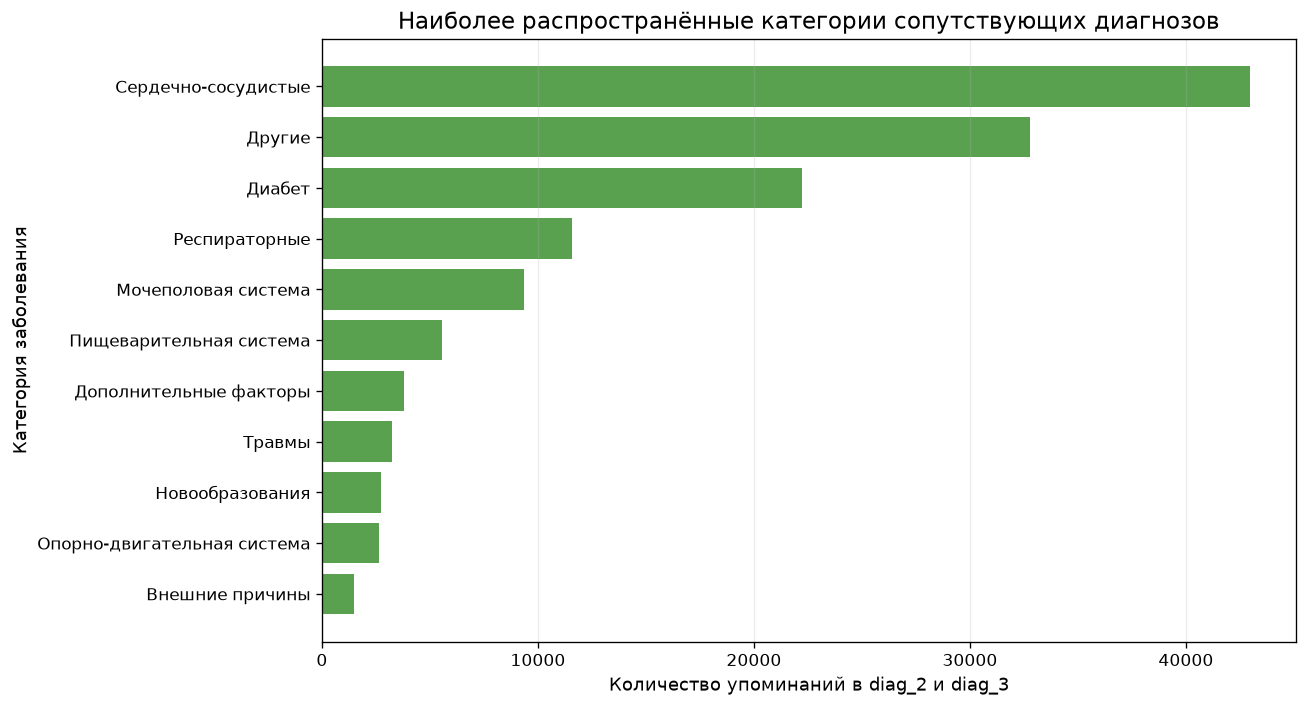

Сохранён график: 07_comorbidity_categories_v2.png


,Количество
Сердечно-сосудистые,42949
Другие,32803
Диабет,22247
Респираторные,11580
Мочеполовая система,9379
Пищеварительная система,5556
Дополнительные факторы,3803
Травмы,3231
Новообразования,2746
Опорно-двигательная система,2663


In [23]:
# Частоты категорий сопутствующих диагнозов diag_2 и diag_3.
comorbidity_categories = pd.concat([
    df_patients["diag_2_category"],
    df_patients["diag_3_category"],
], ignore_index=True)
comorbidity_counts = comorbidity_categories.value_counts().drop(labels=["Не указан"], errors="ignore")

plt.figure(figsize=(11, 6))
plt.barh(comorbidity_counts.index[::-1], comorbidity_counts.values[::-1], color="#59A14F")
plt.title("Наиболее распространённые категории сопутствующих диагнозов")
plt.xlabel("Количество упоминаний в diag_2 и diag_3")
plt.ylabel("Категория заболевания")
plt.grid(axis="x")
save_and_show("07_comorbidity_categories_v2.png")

display(comorbidity_counts.to_frame("Количество"))

,count,mean,"Доля readmitted <30, %"
cardiovascular_disease,,,
Нет сердечно-сосудистого диагноза,29248,0.0837,8.3698
Есть сердечно-сосудистый диагноз,40739,0.0942,9.4185


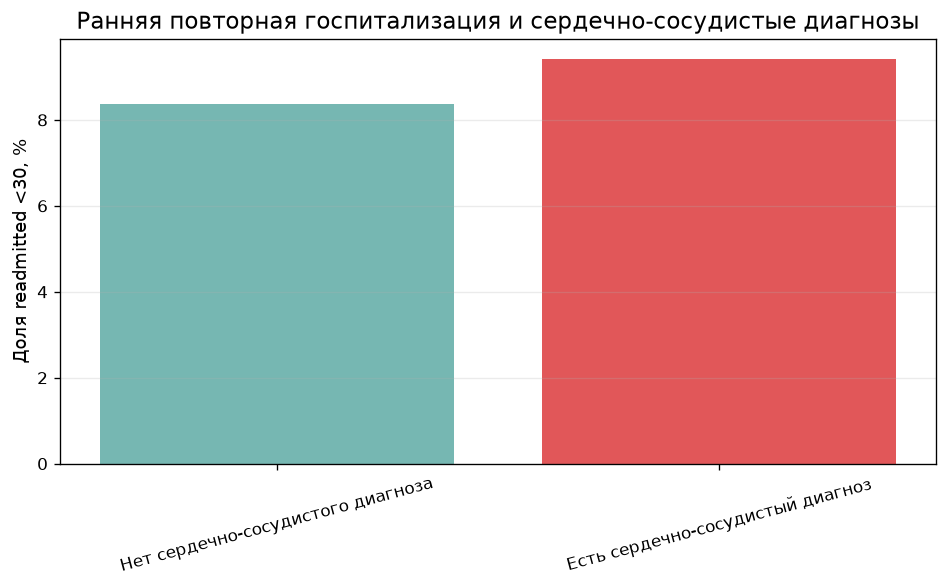

Сохранён график: 08_cardiovascular_readmission_v2.png


In [24]:
cardio_summary = (
    df_patients
    .groupby("cardiovascular_disease")["readmitted_30"]
    .agg(["count", "mean"])
    .rename(index={0: "Нет сердечно-сосудистого диагноза", 1: "Есть сердечно-сосудистый диагноз"})
)
cardio_summary["Доля readmitted <30, %"] = cardio_summary["mean"] * 100

display(cardio_summary)

plt.figure(figsize=(8, 5))
plt.bar(cardio_summary.index, cardio_summary["Доля readmitted <30, %"], color=["#76B7B2", "#E15759"])
plt.title("Ранняя повторная госпитализация и сердечно-сосудистые диагнозы")
plt.ylabel("Доля readmitted <30, %")
plt.xticks(rotation=15)
plt.grid(axis="y")
save_and_show("08_cardiovascular_readmission_v2.png")

,count,mean,median
readmitted_30,,,
Нет readmitted <30,63702,15.5710,14.0000
Есть readmitted <30,6285,16.6204,15.0000


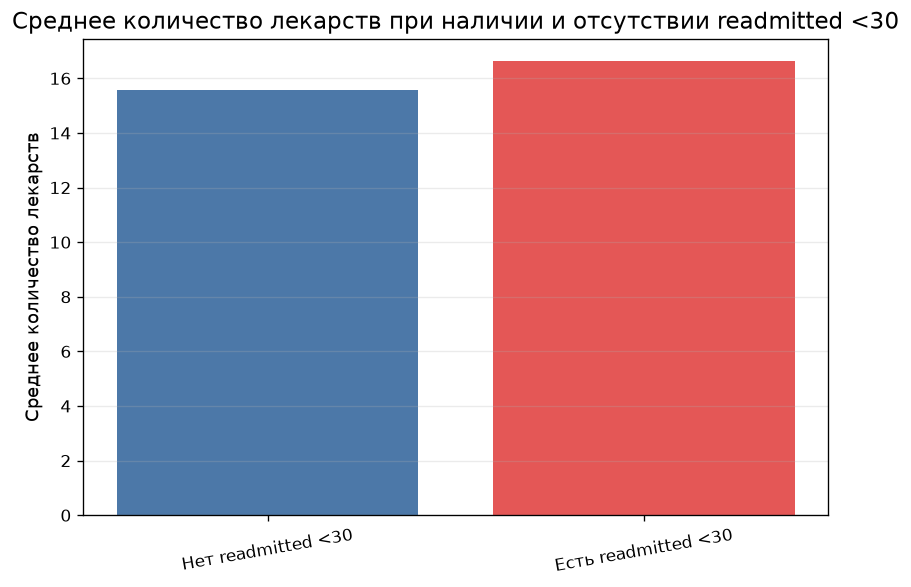

Сохранён график: 09_medications_by_readmission_v2.png


In [25]:
medication_summary = (
    df_patients
    .groupby("readmitted_30")["num_medications"]
    .agg(["count", "mean", "median"])
    .rename(index={0: "Нет readmitted <30", 1: "Есть readmitted <30"})
)
display(medication_summary)

plt.figure(figsize=(7, 5))
plt.bar(medication_summary.index, medication_summary["mean"], color=["#4C78A8", "#E45756"])
plt.title("Среднее количество лекарств при наличии и отсутствии readmitted <30")
plt.ylabel("Среднее количество лекарств")
plt.xticks(rotation=10)
plt.grid(axis="y")
save_and_show("09_medications_by_readmission_v2.png")

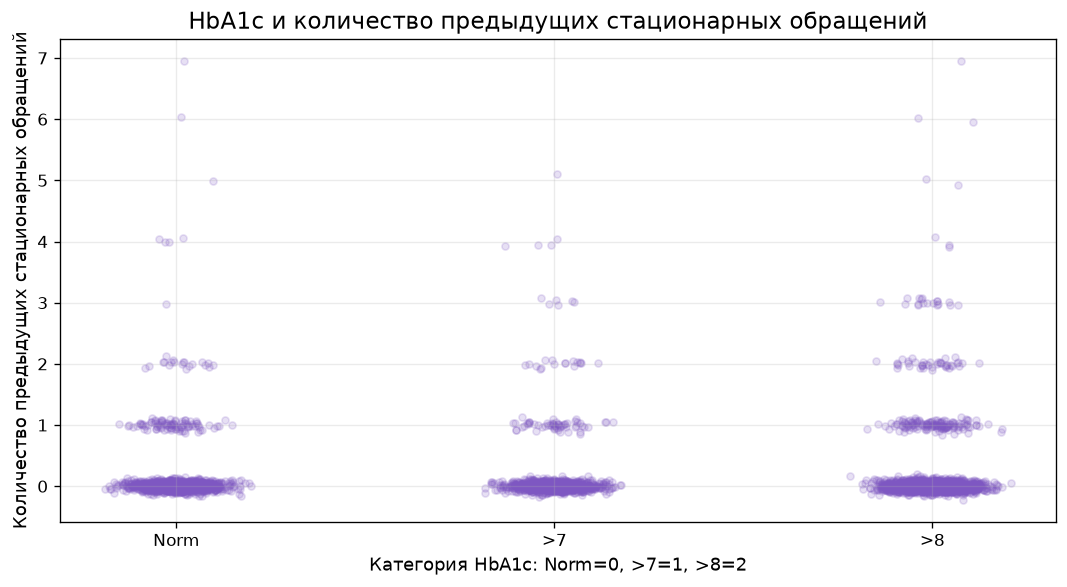

Сохранён график: 10_a1c_vs_inpatient_scatter_v2.png


In [26]:
# Обязательная диаграмма рассеяния: HbA1c vs количество предыдущих госпитализаций.
# HbA1c представлен порядковым кодом: Norm=0, >7=1, >8=2.
a1c_scatter = df_patients[df_patients["a1c_measured"] == 1].copy()
a1c_scatter = a1c_scatter.sample(min(5000, len(a1c_scatter)), random_state=42)

rng = np.random.default_rng(42)
x_jitter = a1c_scatter["a1c_level"] + rng.normal(0, 0.06, len(a1c_scatter))
y_jitter = a1c_scatter["number_inpatient"] + rng.normal(0, 0.05, len(a1c_scatter))

plt.figure(figsize=(9, 5))
plt.scatter(x_jitter, y_jitter, alpha=0.18, s=18, color="#7E57C2")
plt.title("HbA1c и количество предыдущих стационарных обращений")
plt.xlabel("Категория HbA1c: Norm=0, >7=1, >8=2")
plt.ylabel("Количество предыдущих стационарных обращений")
plt.xticks([0, 1, 2], ["Norm", ">7", ">8"])
plt.grid()
save_and_show("10_a1c_vs_inpatient_scatter_v2.png")

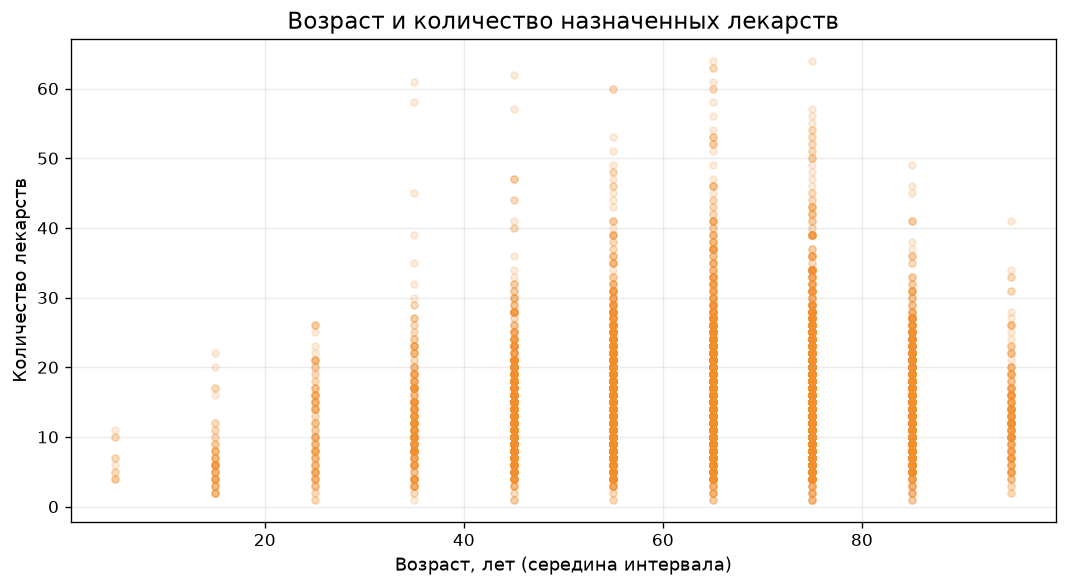

Сохранён график: 11_age_vs_medications_scatter_v2.png


In [27]:
# Обязательная диаграмма рассеяния: возраст vs количество лекарств.
age_med_sample = df_patients.sample(min(6000, len(df_patients)), random_state=42)

plt.figure(figsize=(9, 5))
plt.scatter(
    age_med_sample["age_mid"],
    age_med_sample["num_medications"],
    alpha=0.16,
    s=18,
    color="#F28E2B",
)
plt.title("Возраст и количество назначенных лекарств")
plt.xlabel("Возраст, лет (середина интервала)")
plt.ylabel("Количество лекарств")
plt.grid()
save_and_show("11_age_vs_medications_scatter_v2.png")

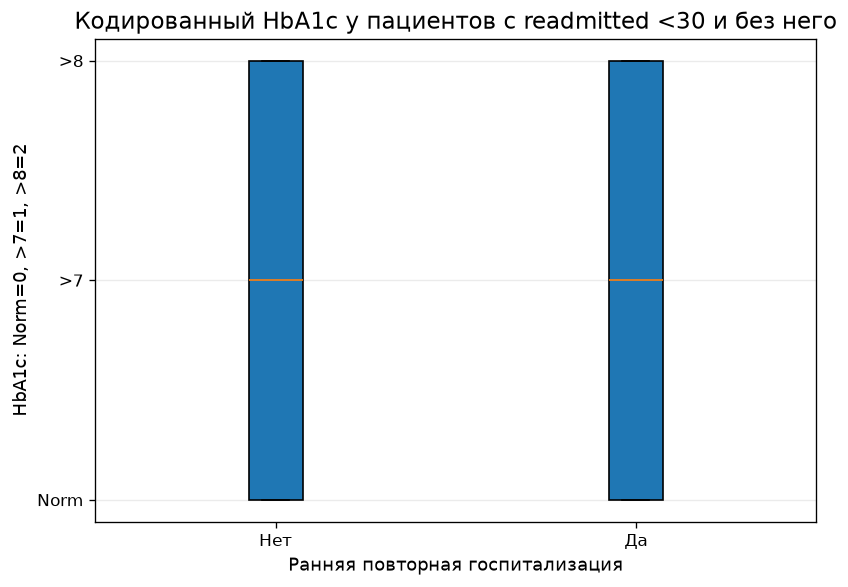

Сохранён график: 12_a1c_boxplot_by_readmission_v2.png


In [28]:
# Boxplot кодированного HbA1c среди пациентов с readmitted <30 и без него.
# Исходный датасет не содержит точного числового значения HbA1c,
# поэтому используется порядковая шкала.

box_no = df_patients.loc[
    (df_patients["readmitted_30"] == 0)
    & (df_patients["a1c_measured"] == 1),
    "a1c_level",
].dropna()

box_yes = df_patients.loc[
    (df_patients["readmitted_30"] == 1)
    & (df_patients["a1c_measured"] == 1),
    "a1c_level",
].dropna()

plt.figure(figsize=(7, 5))

plt.boxplot(
    [box_no, box_yes],
    tick_labels=["Нет", "Да"],
    patch_artist=True,
)

plt.title("Кодированный HbA1c у пациентов с readmitted <30 и без него")
plt.xlabel("Ранняя повторная госпитализация")
plt.ylabel("HbA1c: Norm=0, >7=1, >8=2")
plt.yticks([0, 1, 2], ["Norm", ">7", ">8"])
plt.grid(axis="y")

save_and_show("12_a1c_boxplot_by_readmission_v2.png")

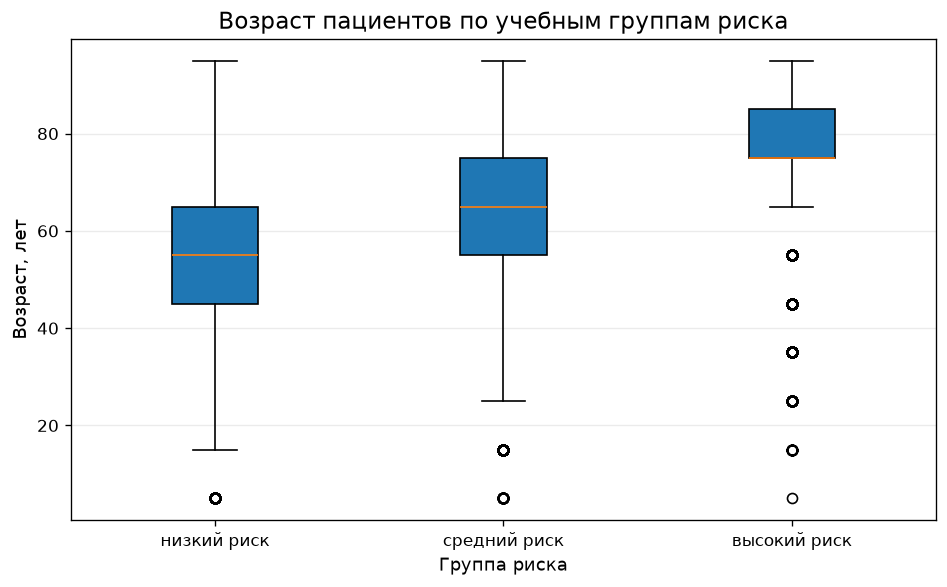

Сохранён график: 13_age_boxplot_by_risk_group_v2.png


In [29]:
risk_order = ["низкий риск", "средний риск", "высокий риск"]

age_by_risk = [
    df_patients.loc[
        df_patients["risk_group"] == group,
        "age_mid",
    ].dropna()
    for group in risk_order
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    age_by_risk,
    tick_labels=risk_order,
    patch_artist=True,
)

plt.title("Возраст пациентов по учебным группам риска")
plt.xlabel("Группа риска")
plt.ylabel("Возраст, лет")
plt.grid(axis="y")

save_and_show("13_age_boxplot_by_risk_group_v2.png")

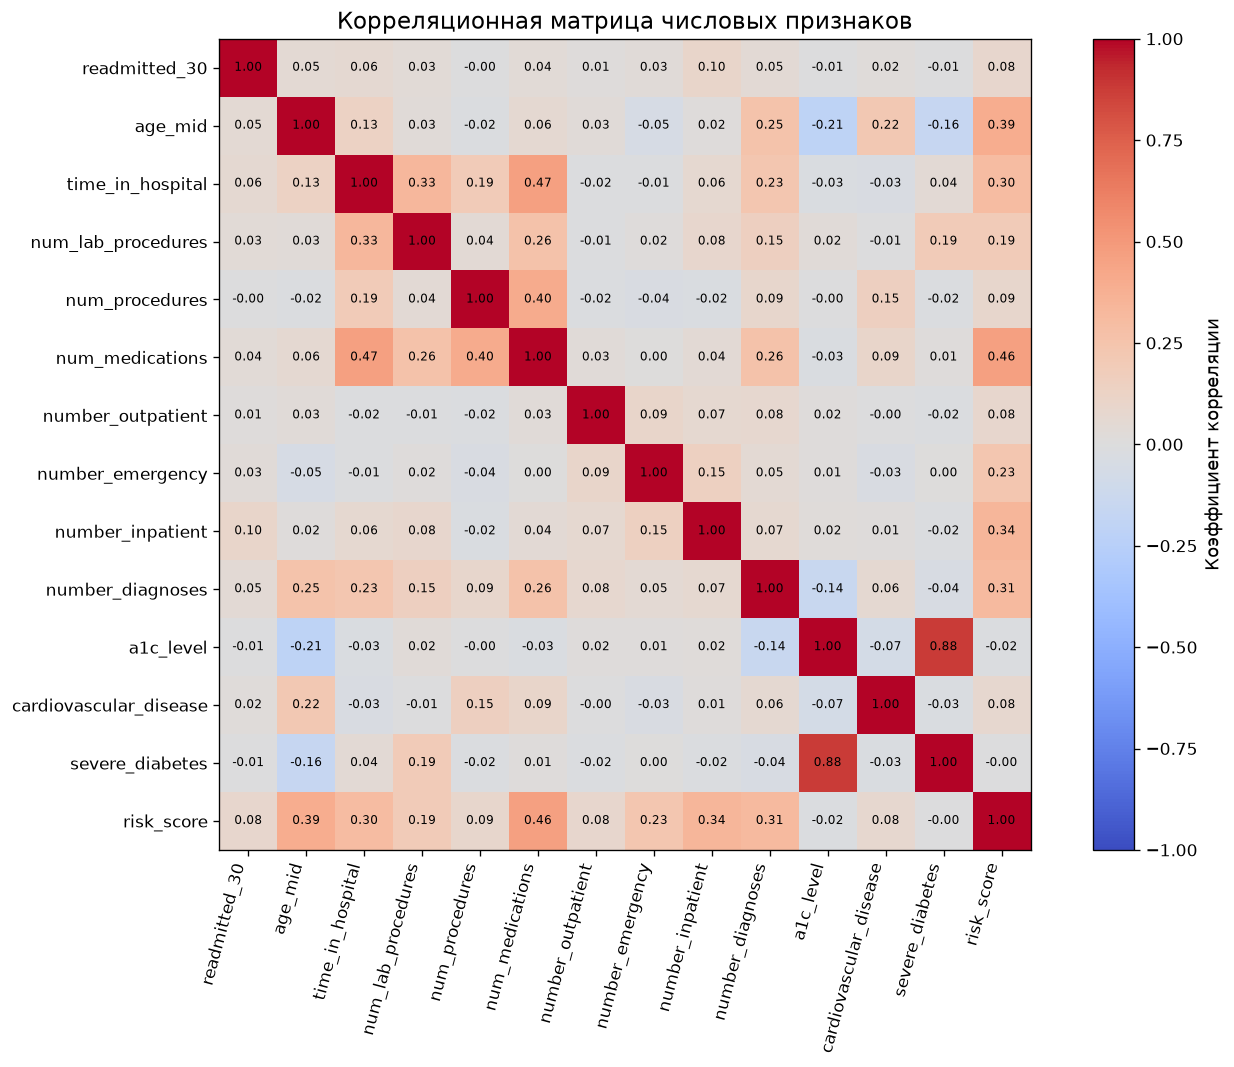

Сохранён график: 14_correlation_heatmap_v2.png


In [30]:
correlation_columns = [
    "readmitted_30", "age_mid", "time_in_hospital", "num_lab_procedures",
    "num_procedures", "num_medications", "number_outpatient",
    "number_emergency", "number_inpatient", "number_diagnoses",
    "a1c_level", "cardiovascular_disease", "severe_diabetes", "risk_score",
]

corr_matrix = df_patients[correlation_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))
ax.set_xticklabels(correlation_columns, rotation=75, ha="right")
ax.set_yticklabels(correlation_columns)

for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)

fig.colorbar(image, ax=ax, label="Коэффициент корреляции")
ax.set_title("Корреляционная матрица числовых признаков")
save_and_show("14_correlation_heatmap_v2.png")

,count,mean,"Доля readmitted <30, %"
race,,,
Caucasian,52305,0.0919,9.1903
AfricanAmerican,12627,0.0867,8.6719
Asian,488,0.0840,8.4016
Hispanic,1501,0.0813,8.1279
Other,1149,0.0688,6.8755


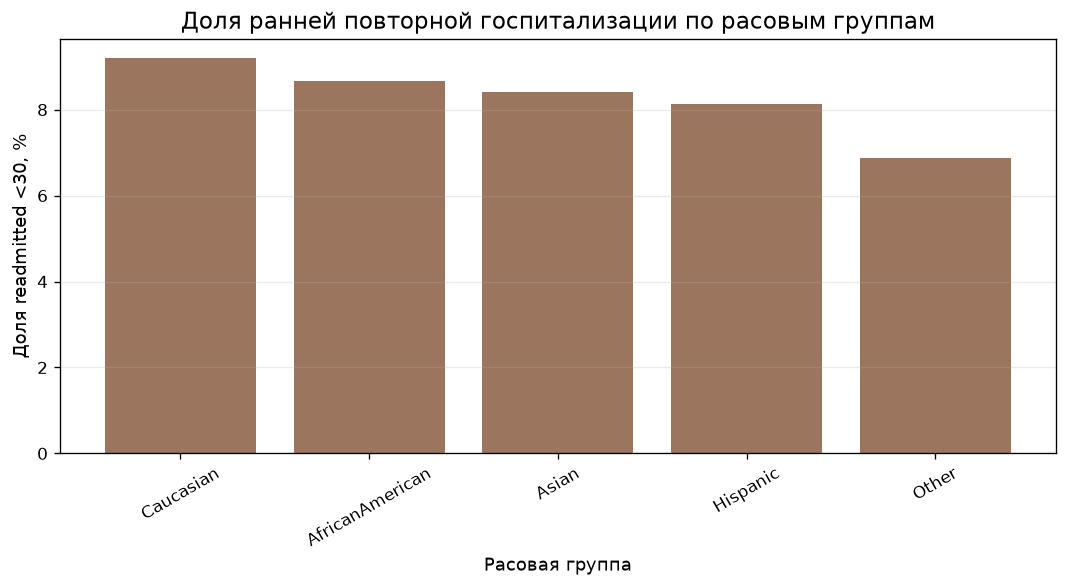

Сохранён график: 15_race_readmission_rate_v2.png


In [31]:
race_known = df_patients[df_patients["race"].notna()].copy()
race_readmission = (
    race_known
    .groupby("race")["readmitted_30"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)
race_readmission["Доля readmitted <30, %"] = race_readmission["mean"] * 100

display(race_readmission)

plt.figure(figsize=(9, 5))
plt.bar(race_readmission.index, race_readmission["Доля readmitted <30, %"], color="#9C755F")
plt.title("Доля ранней повторной госпитализации по расовым группам")
plt.xlabel("Расовая группа")
plt.ylabel("Доля readmitted <30, %")
plt.xticks(rotation=30)
plt.grid(axis="y")
save_and_show("15_race_readmission_rate_v2.png")

,count,mean,"Доля readmitted <30, %"
diagnosis_group,,,
0–2,1074,0.0438,4.3762
3–5,15678,0.0718,7.1757
6 и более,53235,0.0960,9.6046


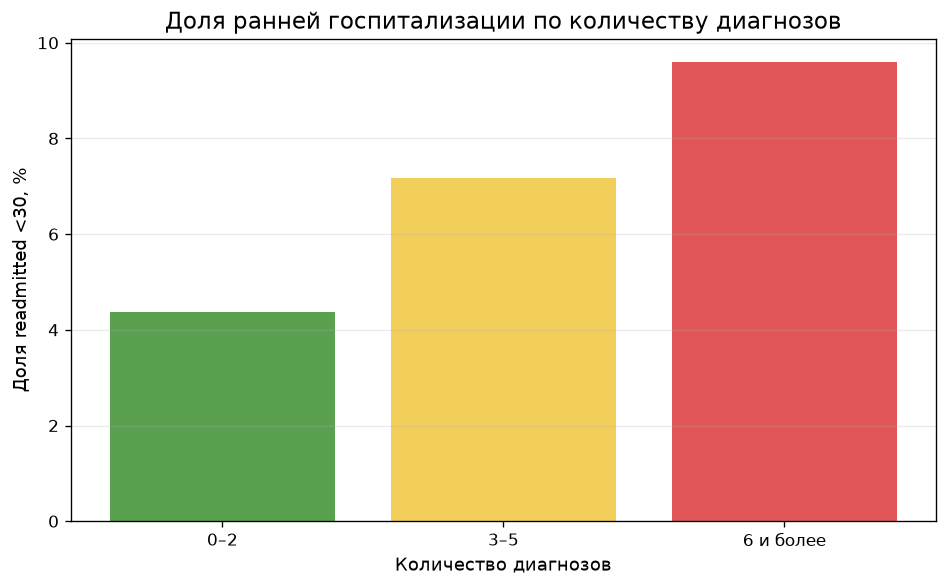

Сохранён график: 16_diagnosis_groups_readmission_v2.png


In [32]:
diagnosis_group_summary = (
    df_patients
    .groupby("diagnosis_group", observed=False)["readmitted_30"]
    .agg(["count", "mean"])
)
diagnosis_group_summary["Доля readmitted <30, %"] = diagnosis_group_summary["mean"] * 100

display(diagnosis_group_summary)

plt.figure(figsize=(8, 5))
plt.bar(
    diagnosis_group_summary.index.astype(str),
    diagnosis_group_summary["Доля readmitted <30, %"],
    color=["#59A14F", "#F2CF5B", "#E15759"],
)
plt.title("Доля ранней госпитализации по количеству диагнозов")
plt.xlabel("Количество диагнозов")
plt.ylabel("Доля readmitted <30, %")
plt.grid(axis="y")
save_and_show("16_diagnosis_groups_readmission_v2.png")

Пропуски medical_specialty: 48.08%


,count,mean,"Доля readmitted <30, %"
medical_specialty,,,
InternalMedicine,10641,0.0976,9.7641
Family/GeneralPractice,4978,0.0974,9.7429
Emergency/Trauma,4393,0.0783,7.8306
Cardiology,4207,0.0720,7.2023
Surgery-General,2205,0.0834,8.3447
Orthopedics,1128,0.0993,9.9291
Orthopedics-Reconstructive,1041,0.0663,6.6282
Radiologist,821,0.0706,7.0646
Nephrology,797,0.1104,11.0414


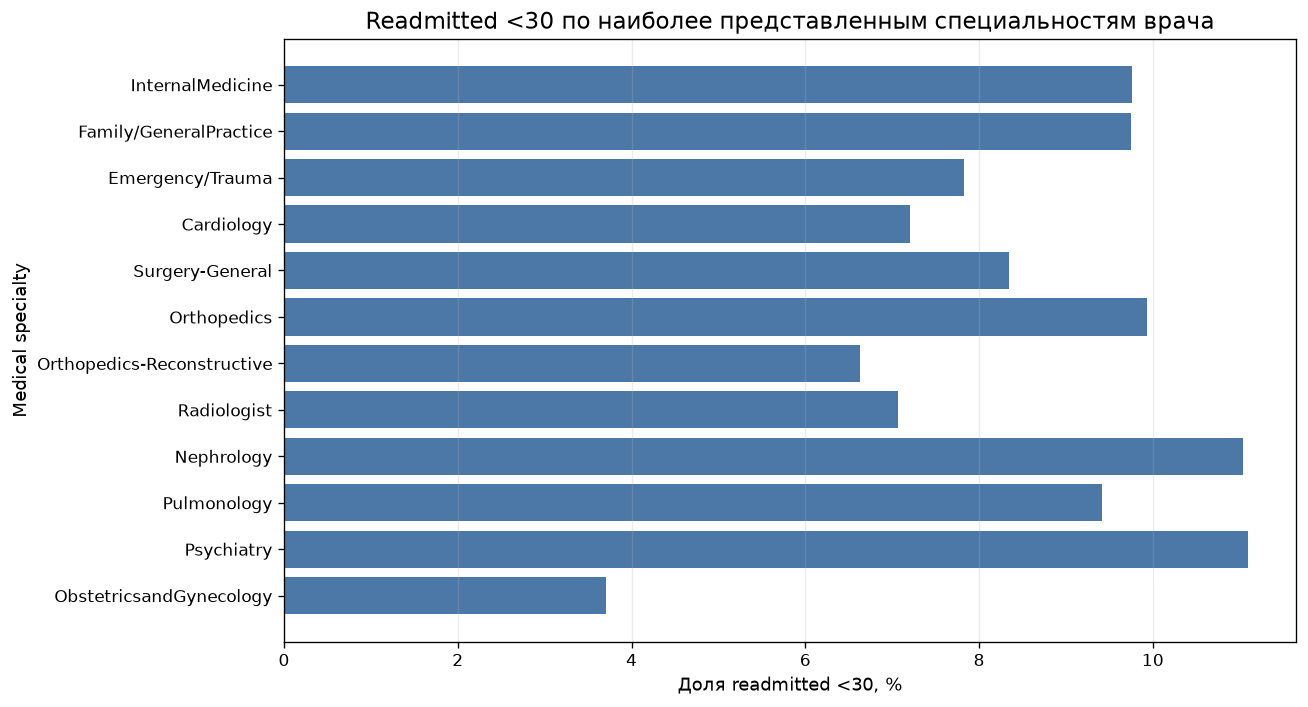

Сохранён график: 17_medical_specialty_proxy_v2.png


In [33]:
# Поле medical_specialty используется только как ограниченный прокси-показатель
# доступности специализированной помощи. В нём много пропусков.
specialty_missing_rate = df_patients["medical_specialty"].isna().mean() * 100
specialty_known = df_patients[df_patients["medical_specialty"].notna()].copy()

specialty_summary = (
    specialty_known
    .groupby("medical_specialty")["readmitted_30"]
    .agg(["count", "mean"])
)
specialty_summary = specialty_summary[specialty_summary["count"] >= 300]
specialty_summary = specialty_summary.sort_values("count", ascending=False).head(12)
specialty_summary["Доля readmitted <30, %"] = specialty_summary["mean"] * 100

print(f"Пропуски medical_specialty: {specialty_missing_rate:.2f}%")
display(specialty_summary)

plt.figure(figsize=(11, 6))
plt.barh(
    specialty_summary.index[::-1],
    specialty_summary["Доля readmitted <30, %"][::-1],
    color="#4C78A8",
)
plt.title("Readmitted <30 по наиболее представленным специальностям врача")
plt.xlabel("Доля readmitted <30, %")
plt.ylabel("Medical specialty")
plt.grid(axis="x")
save_and_show("17_medical_specialty_proxy_v2.png")

### Ограничение анализа специализированной помощи и социально-экономических факторов

В датасете отсутствуют прямые признаки дохода, образования, страхового статуса в полном виде и типа медицинской организации. Поэтому влияние социально-экономического положения и доступности специализированной помощи невозможно оценить напрямую. Поле `medical_specialty` используется только как ограниченный прокси-показатель и содержит значительную долю пропусков.

# 5. Проверка статистических гипотез

Все пять гипотез проверяются на пациент-уровневой выборке. Уровень статистической значимости принят равным `α = 0,05`. Для категориальных признаков применяется критерий хи-квадрат Пирсона. Помимо `p-value` рассчитываются доли, относительный риск, Odds Ratio и V Крамера. Малое значение `p-value` не означает сильный практический эффект, поэтому сила связи интерпретируется отдельно.

In [34]:
ALPHA = 0.05

FACTOR_LABELS = {
    "a1c_high_8": "HbA1c > 8%",
    "diagnoses_3plus": "3 и более диагнозов",
    "older_70": "Возраст старше 70 лет",
    "gender": "Пол",
    "race": "Раса",
}


def cramers_v(contingency_table):
    chi2, _, _, _ = chi2_contingency(contingency_table)
    n = contingency_table.to_numpy().sum()
    denominator = min(contingency_table.shape[0] - 1, contingency_table.shape[1] - 1)
    return np.sqrt(chi2 / (n * denominator)) if denominator > 0 else np.nan


def binary_hypothesis(data, factor, number, hypothesis_text):
    subset = data[[factor, "readmitted_30"]].dropna().copy()
    table = pd.crosstab(subset[factor], subset["readmitted_30"])
    chi2, p_value, dof, _ = chi2_contingency(table)

    rates = subset.groupby(factor)["readmitted_30"].agg(["count", "mean"])
    rate_0 = rates.loc[0, "mean"]
    rate_1 = rates.loc[1, "mean"]
    relative_risk = rate_1 / rate_0 if rate_0 > 0 else np.nan

    a = table.loc[1, 1]
    b = table.loc[1, 0]
    c = table.loc[0, 1]
    d = table.loc[0, 0]
    odds_ratio = (a / b) / (c / d)

    direction_is_expected = rate_1 > rate_0
    confirmed = (p_value < ALPHA) and direction_is_expected

    return {
        "№": number,
        "Гипотеза": hypothesis_text,
        "Фактор": FACTOR_LABELS.get(factor, factor),
        "N": len(subset),
        "Риск без фактора, %": rate_0 * 100,
        "Риск с фактором, %": rate_1 * 100,
        "Разница, п.п.": (rate_1 - rate_0) * 100,
        "Относительный риск": relative_risk,
        "Odds Ratio": odds_ratio,
        "chi2": chi2,
        "p-value": p_value,
        "Cramer's V": cramers_v(table),
        "Итог": "подтверждается" if confirmed else "не подтверждается",
    }, table, rates


def categorical_hypothesis(data, factor, number, hypothesis_text):
    subset = data[[factor, "readmitted_30"]].dropna().copy()
    table = pd.crosstab(subset[factor], subset["readmitted_30"])
    chi2, p_value, dof, _ = chi2_contingency(table)
    rates = subset.groupby(factor)["readmitted_30"].agg(["count", "mean"])

    return {
        "№": number,
        "Гипотеза": hypothesis_text,
        "Фактор": FACTOR_LABELS.get(factor, factor),
        "N": len(subset),
        "Риск без фактора, %": np.nan,
        "Риск с фактором, %": np.nan,
        "Разница, п.п.": (rates["mean"].max() - rates["mean"].min()) * 100,
        "Относительный риск": np.nan,
        "Odds Ratio": np.nan,
        "chi2": chi2,
        "p-value": p_value,
        "Cramer's V": cramers_v(table),
        "Итог": "подтверждается" if p_value < ALPHA else "не подтверждается",
    }, table, rates

In [35]:
hypothesis_details = []

# H1: сравниваются только пациенты, у которых HbA1c действительно измерялся.
h1_data = df_patients[df_patients["a1c_measured"] == 1].copy()
h1, h1_table, h1_rates = binary_hypothesis(
    h1_data,
    "a1c_high_8",
    1,
    "Пациенты с HbA1c > 8% имеют более высокий риск readmitted <30",
)
hypothesis_details.append(h1)

h2, h2_table, h2_rates = binary_hypothesis(
    df_patients,
    "diagnoses_3plus",
    2,
    "Наличие трёх и более диагнозов увеличивает вероятность readmitted <30",
)
hypothesis_details.append(h2)

h3, h3_table, h3_rates = binary_hypothesis(
    df_patients,
    "older_70",
    3,
    "Пациенты старше 70 лет чаще госпитализируются повторно",
)
hypothesis_details.append(h3)

h4_data = df_patients[df_patients["gender"].isin(["Male", "Female"])].copy()
h4, h4_table, h4_rates = categorical_hypothesis(
    h4_data,
    "gender",
    4,
    "Мужчины и женщины имеют разный риск readmitted <30",
)
hypothesis_details.append(h4)

h5_data = df_patients[df_patients["race"].notna()].copy()
h5, h5_table, h5_rates = categorical_hypothesis(
    h5_data,
    "race",
    5,
    "Раса пациента связана с вероятностью readmitted <30",
)
hypothesis_details.append(h5)

hypothesis_results = pd.DataFrame(hypothesis_details)

# Числа сохраняются без преждевременного округления.
display_columns = [
    "№", "Гипотеза", "N", "Риск без фактора, %", "Риск с фактором, %",
    "Разница, п.п.", "Относительный риск", "Odds Ratio", "p-value",
    "Cramer's V", "Итог",
]

display(hypothesis_results[display_columns].round(6))

hypothesis_results.to_csv(
    HYPOTHESES_DIR / "hypothesis_results_v2.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nДоли по гипотезе 1:")
display(h1_rates)
print("\nДоли по гипотезе 4:")
display(h4_rates)
print("\nДоли по гипотезе 5:")
display(h5_rates)

,№,Гипотеза,N,"Риск без фактора, %","Риск с фактором, %","Разница, п.п.",Относительный риск,Odds Ratio,p-value,Cramer's V,Итог
0,1,Пациенты с HbA1c > 8% имеют более высокий риск...,12846,8.6272,8.1584,-0.4689,0.9457,0.9408,0.3546,0.0082,не подтверждается
1,2,Наличие трёх и более диагнозов увеличивает вер...,69987,4.3762,9.0520,4.6758,2.0685,2.1748,0.0000,0.0199,подтверждается
2,3,Пациенты старше 70 лет чаще госпитализируются ...,69987,7.8772,10.3984,2.5213,1.3201,1.3572,0.0000,0.0437,подтверждается
3,4,Мужчины и женщины имеют разный риск readmitted...,69987,NaN,NaN,0.1197,NaN,NaN,0.5898,0.0020,не подтверждается
4,5,Раса пациента связана с вероятностью readmitte...,68070,NaN,NaN,2.3148,NaN,NaN,0.0187,0.0132,подтверждается



Доли по гипотезе 1:


,count,mean
a1c_high_8,,
0,6607,0.0863
1,6239,0.0816



Доли по гипотезе 4:


,count,mean
gender,,
Female,37239,0.0904
Male,32748,0.0892



Доли по гипотезе 5:


,count,mean
race,,
AfricanAmerican,12627,0.0867
Asian,488,0.0840
Caucasian,52305,0.0919
Hispanic,1501,0.0813
Other,1149,0.0688


In [36]:
# Анализ устойчивости гипотезы 5 на всех госпитализационных эпизодах.
h5_sensitivity_data = encounter_race_readmission[encounter_race_readmission["race"].notna()].copy()
h5_sensitivity_table = pd.crosstab(
    h5_sensitivity_data["race"],
    h5_sensitivity_data["readmitted_30"],
)
_, h5_sensitivity_p, _, _ = chi2_contingency(h5_sensitivity_table)

print(f"H5, первый эпизод каждого пациента: p-value = {h5['p-value']:.6g}")
print(f"H5, все госпитализационные эпизоды: p-value = {h5_sensitivity_p:.6g}")
print(
    "Вывод: результат по расе является статистически слабым и чувствительным "
    "к способу формирования выборки, поэтому требует осторожной интерпретации."
)

# Сохраняем значение для итоговой формулировки.
hypothesis_results.loc[hypothesis_results["№"] == 5, "Итог"] = (
    "частично подтверждается: связь слабая и неустойчивая"
)
hypothesis_results.to_csv(
    HYPOTHESES_DIR / "hypothesis_results_v2.csv",
    index=False,
    encoding="utf-8-sig",
)

H5, первый эпизод каждого пациента: p-value = 0.0186991
H5, все госпитализационные эпизоды: p-value = 0.139039
Вывод: результат по расе является статистически слабым и чувствительным к способу формирования выборки, поэтому требует осторожной интерпретации.


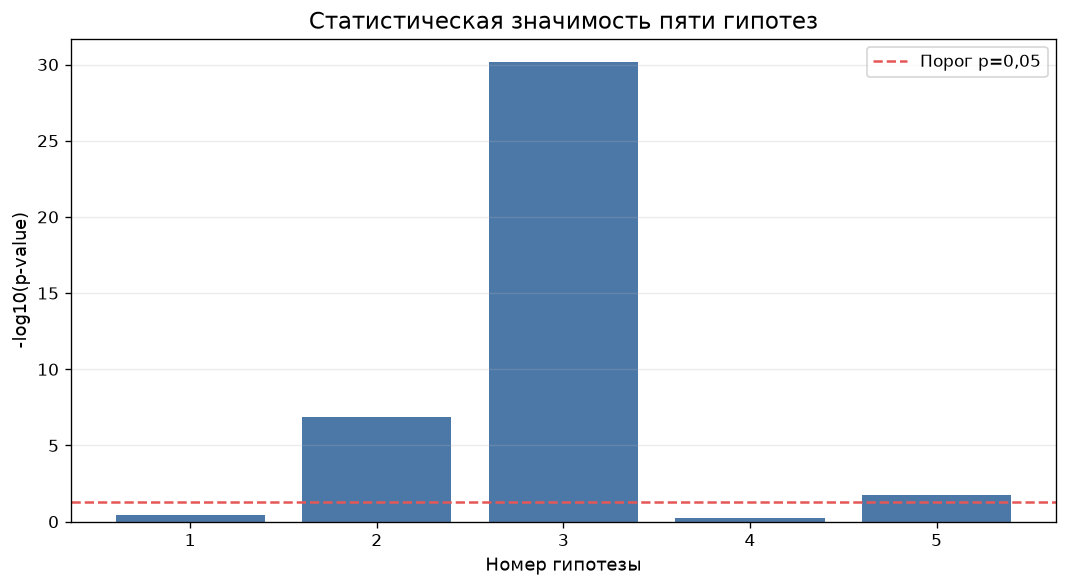

Сохранён график: 18_hypotheses_significance_v2.png


In [37]:
plot_values = -np.log10(hypothesis_results["p-value"].clip(lower=1e-300))

plt.figure(figsize=(9, 5))
plt.bar(hypothesis_results["№"].astype(str), plot_values, color="#4C78A8")
plt.axhline(-np.log10(ALPHA), color="#E45756", linestyle="--", label="Порог p=0,05")
plt.title("Статистическая значимость пяти гипотез")
plt.xlabel("Номер гипотезы")
plt.ylabel("-log10(p-value)")
plt.legend()
plt.grid(axis="y")
save_and_show("18_hypotheses_significance_v2.png")

In [38]:
for _, row in hypothesis_results.iterrows():
    p_text = f"{row['p-value']:.6g}"
    cramers_value = row["Cramer's V"]
    print(f"Гипотеза {int(row['№'])}: {row['Итог']}; p-value = {p_text}; Cramer's V = {cramers_value:.4f}")

print("\nИнтерпретация:")
print("1) HbA1c > 8% не показал статистически значимого повышения риска среди пациентов с измеренным HbA1c.")
print("2) Три и более диагноза связаны с повышением риска, однако связь слабая.")
print("3) Возраст старше 70 лет связан с повышением риска; сила связи остаётся небольшой.")
print("4) Статистически значимых различий между мужчинами и женщинами не обнаружено.")
print("5) Различия по расе выявлены на пациент-уровне, но эффект слабый и неустойчивый при анализе всех эпизодов.")

Гипотеза 1: не подтверждается; p-value = 0.354613; Cramer's V = 0.0082
Гипотеза 2: подтверждается; p-value = 1.40387e-07; Cramer's V = 0.0199
Гипотеза 3: подтверждается; p-value = 6.54942e-31; Cramer's V = 0.0437
Гипотеза 4: не подтверждается; p-value = 0.589755; Cramer's V = 0.0020
Гипотеза 5: частично подтверждается: связь слабая и неустойчивая; p-value = 0.0186991; Cramer's V = 0.0132

Интерпретация:
1) HbA1c > 8% не показал статистически значимого повышения риска среди пациентов с измеренным HbA1c.
2) Три и более диагноза связаны с повышением риска, однако связь слабая.
3) Возраст старше 70 лет связан с повышением риска; сила связи остаётся небольшой.
4) Статистически значимых различий между мужчинами и женщинами не обнаружено.
5) Различия по расе выявлены на пациент-уровне, но эффект слабый и неустойчивый при анализе всех эпизодов.


# 6. Решение: выявление и ранжирование факторов риска

В аналитической части оцениваются бинарные факторы риска. Для каждого фактора рассчитываются доли ранней повторной госпитализации при наличии и отсутствии фактора, разница в процентных пунктах, относительный риск, Odds Ratio, `p-value` и V Крамера.

In [39]:
RISK_FACTOR_LABELS = {
    "had_previous_inpatient": "Предыдущие стационарные обращения",
    "had_emergency_visits": "Экстренные обращения",
    "had_outpatient_visits": "Амбулаторные обращения",
    "older_70": "Возраст старше 70 лет",
    "diagnoses_3plus": "3 и более диагнозов",
    "many_medications": f"Лекарств не меньше медианы ({medication_threshold:.0f})",
    "insulin_used": "Использование инсулина",
    "treatment_changed": "Изменение лечения",
    "glucose_high": "Повышенная глюкоза",
    "cardiovascular_disease": "Сердечно-сосудистый диагноз",
    "severe_diabetes": "Учебный индикатор тяжёлого течения",
    "a1c_high_8": "HbA1c > 8%",
}


def binary_factor_statistics(data, factor):
    result, _, _ = binary_hypothesis(
        data,
        factor,
        0,
        RISK_FACTOR_LABELS.get(factor, factor),
    )
    return {
        "Фактор": RISK_FACTOR_LABELS.get(factor, factor),
        "N": result["N"],
        "Риск без фактора, %": result["Риск без фактора, %"],
        "Риск с фактором, %": result["Риск с фактором, %"],
        "Разница, п.п.": result["Разница, п.п."],
        "Относительный риск": result["Относительный риск"],
        "Odds Ratio": result["Odds Ratio"],
        "p-value": result["p-value"],
        "Cramer's V": result["Cramer's V"],
    }

candidate_factors = [
    "had_previous_inpatient", "had_emergency_visits", "had_outpatient_visits",
    "older_70", "diagnoses_3plus", "many_medications", "insulin_used",
    "treatment_changed", "glucose_high", "cardiovascular_disease",
    "severe_diabetes", "a1c_high_8",
]

risk_factor_ranking = pd.DataFrame([
    binary_factor_statistics(df_patients, factor)
    for factor in candidate_factors
])
risk_factor_ranking = risk_factor_ranking.sort_values("Разница, п.п.", ascending=False)

display(risk_factor_ranking.round(6))
risk_factor_ranking.to_csv(
    RISK_DIR / "risk_factor_ranking_v2.csv",
    index=False,
    encoding="utf-8-sig",
)

,Фактор,N,"Риск без фактора, %","Риск с фактором, %","Разница, п.п.",Относительный риск,Odds Ratio,p-value,Cramer's V
0,Предыдущие стационарные обращения,69987,8.1289,15.3996,7.2707,1.8944,2.0572,0.0000,0.0817
4,3 и более диагнозов,69987,4.3762,9.0520,4.6758,2.0685,2.1748,0.0000,0.0199
1,Экстренные обращения,69987,8.7415,12.0173,3.2758,1.3747,1.4259,0.0000,0.0297
3,Возраст старше 70 лет,69987,7.8772,10.3984,2.5213,1.3201,1.3572,0.0000,0.0437
5,Лекарств не меньше медианы (14),69987,7.8982,9.8928,1.9946,1.2525,1.2803,0.0000,0.0347
8,Повышенная глюкоза,69987,8.9422,10.5583,1.6161,1.1807,1.2021,0.0262,0.0084
2,Амбулаторные обращения,69987,8.7998,10.1842,1.3844,1.1573,1.1752,0.0000,0.0162
6,Использование инсулина,69987,8.2971,9.6355,1.3384,1.1613,1.1785,0.0000,0.0234
9,Сердечно-сосудистый диагноз,69987,8.3698,9.4185,1.0487,1.1253,1.1383,0.0000,0.0180
7,Изменение лечения,69987,8.6044,9.4396,0.8352,1.0971,1.1072,0.0001,0.0145


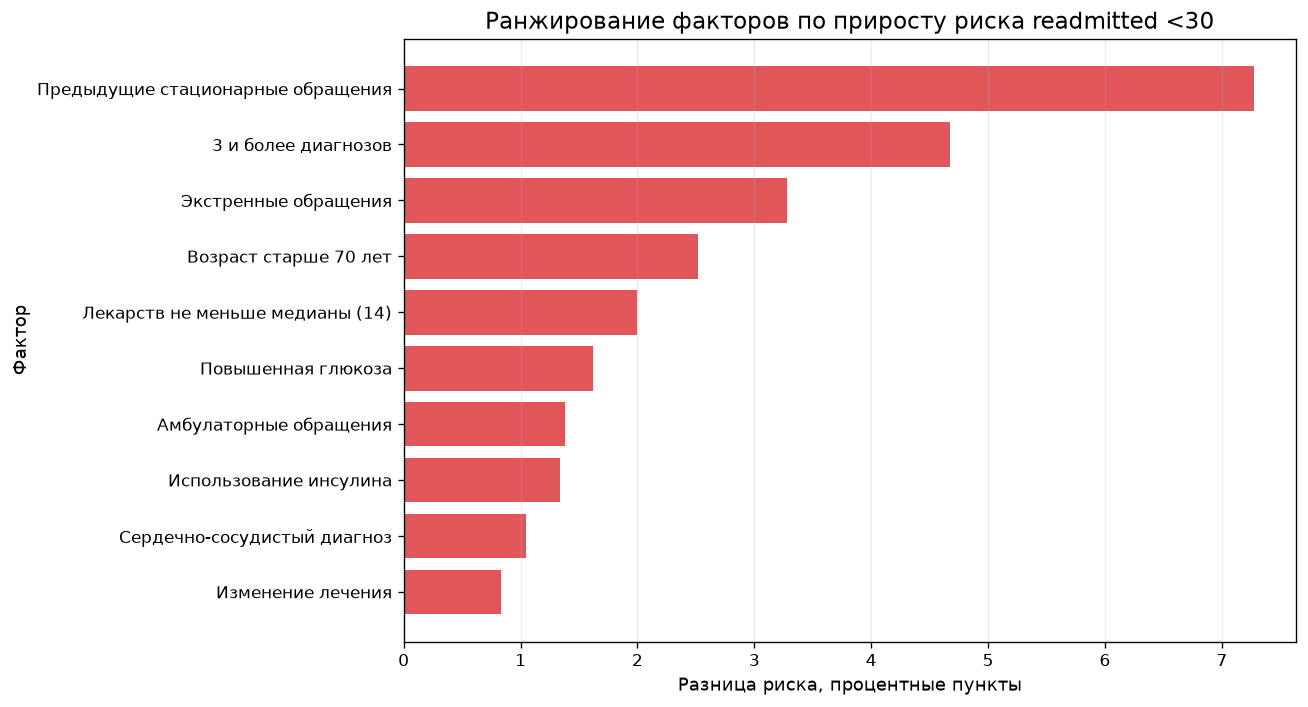

Сохранён график: 19_top_risk_factors_v2.png


In [40]:
positive_risk_factors = risk_factor_ranking[risk_factor_ranking["Разница, п.п."] > 0].head(10)

plt.figure(figsize=(11, 6))
plt.barh(
    positive_risk_factors["Фактор"][::-1],
    positive_risk_factors["Разница, п.п."][::-1],
    color="#E15759",
)
plt.title("Ранжирование факторов по приросту риска readmitted <30")
plt.xlabel("Разница риска, процентные пункты")
plt.ylabel("Фактор")
plt.grid(axis="x")
save_and_show("19_top_risk_factors_v2.png")

,count,mean,"Доля readmitted <30, %"
risk_group,,,
низкий риск,9300,0.0557,5.5699
средний риск,45945,0.0848,8.4841
высокий риск,14742,0.1268,12.6781


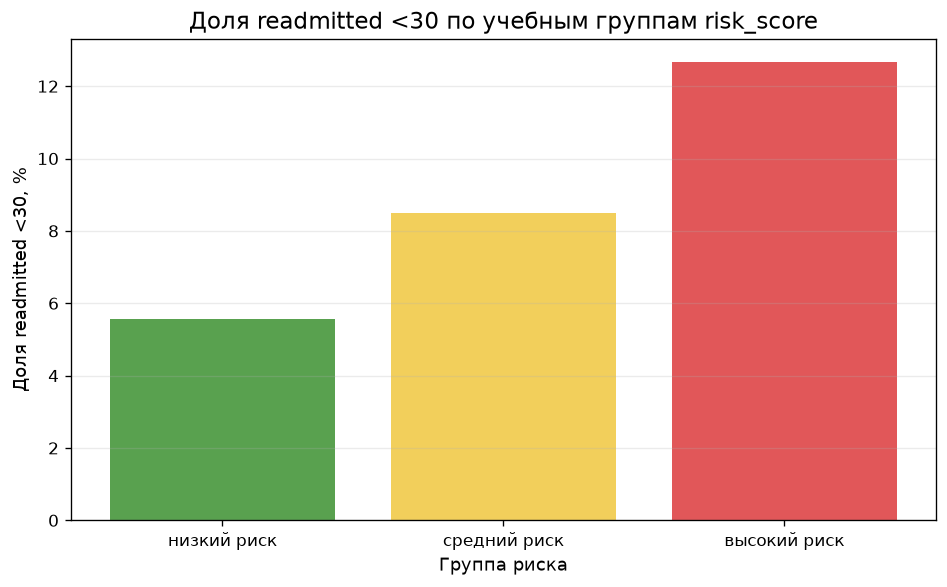

Сохранён график: 20_risk_group_readmission_v2.png


In [41]:
risk_group_summary = (
    df_patients
    .groupby("risk_group", observed=False)["readmitted_30"]
    .agg(["count", "mean"])
)
risk_group_summary["Доля readmitted <30, %"] = risk_group_summary["mean"] * 100

display(risk_group_summary)

plt.figure(figsize=(8, 5))
plt.bar(
    risk_group_summary.index.astype(str),
    risk_group_summary["Доля readmitted <30, %"],
    color=["#59A14F", "#F2CF5B", "#E15759"],
)
plt.title("Доля readmitted <30 по учебным группам risk_score")
plt.xlabel("Группа риска")
plt.ylabel("Доля readmitted <30, %")
plt.grid(axis="y")
save_and_show("20_risk_group_readmission_v2.png")

risk_group_summary.to_csv(
    RISK_DIR / "risk_group_summary_v2.csv",
    encoding="utf-8-sig",
)

In [42]:
# Исследовательский подбор порогов. Порог выбирается по максимальной положительной
# разнице риска при условии, что в обеих группах находится не менее 5% выборки.
def evaluate_threshold(data, column, thresholds):
    rows = []
    for threshold in thresholds:
        indicator = (data[column] >= threshold).astype(int)
        counts = indicator.value_counts()
        if len(counts) < 2 or counts.min() < 0.05 * len(data):
            continue
        rates = data.groupby(indicator)["readmitted_30"].mean()
        rows.append({
            "Признак": column,
            "Порог": threshold,
            "Риск ниже порога, %": rates.loc[0] * 100,
            "Риск от порога и выше, %": rates.loc[1] * 100,
            "Разница, п.п.": (rates.loc[1] - rates.loc[0]) * 100,
        })
    return rows

threshold_candidates = {
    "age_mid": [50, 60, 70, 80],
    "number_diagnoses": [3, 6, 9],
    "num_medications": [10, 15, 20, 25],
    "number_inpatient": [1, 2, 3],
    "number_emergency": [1, 2],
    "time_in_hospital": [4, 7, 10],
    "num_lab_procedures": [30, 50, 70],
}

threshold_rows = []
for column, thresholds in threshold_candidates.items():
    threshold_rows.extend(evaluate_threshold(df_patients, column, thresholds))

threshold_analysis = pd.DataFrame(threshold_rows)
best_thresholds = (
    threshold_analysis
    .sort_values("Разница, п.п.", ascending=False)
    .groupby("Признак", as_index=False)
    .first()
    .sort_values("Разница, п.п.", ascending=False)
)

display(best_thresholds.round(3))
best_thresholds.to_csv(
    RISK_DIR / "exploratory_thresholds_v2.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Пороги являются исследовательскими и получены на текущей выборке. "
    "Они не должны использоваться как клинические нормативы без внешней проверки."
)

,Признак,Порог,"Риск ниже порога, %","Риск от порога и выше, %","Разница, п.п."
5,number_inpatient,1,8.1290,15.4000,7.2710
6,time_in_hospital,7,8.3230,11.6890,3.3660
4,number_emergency,1,8.7410,12.0170,3.2760
0,age_mid,60,7.1200,9.9310,2.8110
3,number_diagnoses,6,6.9960,9.6050,2.6080
2,num_medications,10,7.1400,9.5100,2.3700
1,num_lab_procedures,30,7.5260,9.4200,1.8940


Пороги являются исследовательскими и получены на текущей выборке. Они не должны использоваться как клинические нормативы без внешней проверки.


In [43]:
# Формируем согласованный датасет для обновлённого Flet-приложения.
flet_columns = [
    "encounter_id", "patient_nbr", "race", "gender", "age", "age_mid", "age_group",
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
    "A1Cresult", "max_glu_serum", "medical_specialty", "diag_1", "diag_2", "diag_3",
    "diag_1_category", "diag_2_category", "diag_3_category",
    "cardiovascular_disease", "insulin", "change", "diabetesMed", "readmitted",
    "readmitted_30", "a1c_measured", "a1c_high_8", "a1c_level", "glucose_high",
    "diagnosis_count", "diagnoses_3plus", "diagnosis_group", "older_70",
    "had_previous_inpatient", "had_emergency_visits", "had_outpatient_visits",
    "medications_count", "many_medications", "active_diabetes_medications_count",
    "insulin_used", "treatment_changed", "severe_diabetes", "risk_score", "risk_group",
]
flet_columns = [column for column in flet_columns if column in df_patients.columns]

flet_ready = df_patients[flet_columns].copy()
flet_ready_path = OUTPUTS_DIR / "flet_ready_diabetes_data_v2.csv"
flet_ready.to_csv(flet_ready_path, index=False, encoding="utf-8-sig")

# При стандартной структуре проекта обновляем файл приложения автоматически.
project_root = BASE_DIR.parent
flet_destination = project_root / "04_Flet_app" / "data" / "flet_ready_diabetes_data.csv"

if flet_destination.parent.exists():
    flet_ready.to_csv(flet_destination, index=False, encoding="utf-8-sig")
    print("Данные для Flet обновлены:", flet_destination.name)
else:
    print("Файл для Flet сохранён только в outputs:", flet_ready_path.name)

print("Размер Flet-таблицы:", flet_ready.shape)

Данные для Flet обновлены: flet_ready_diabetes_data.csv
Размер Flet-таблицы: (69987, 49)


# 7. Выводы

В итоговом разделе обобщаются результаты, формулируются рекомендации, ограничения и возможные направления развития работы.

In [44]:
confirmed_hypotheses = hypothesis_results.loc[
    hypothesis_results["Итог"].astype(str).str.startswith("подтверждается"),
    "№",
].astype(int).tolist()

not_confirmed_hypotheses = hypothesis_results.loc[
    hypothesis_results["Итог"] == "не подтверждается",
    "№",
].astype(int).tolist()

top_factors = risk_factor_ranking.head(5)[["Фактор", "Разница, п.п.", "Относительный риск"]]

print("ИТОГОВАЯ СВОДКА")
print("=" * 80)
print(f"Исходных госпитализационных эпизодов: {raw_encounter_count:,}".replace(",", " "))
print(f"Очищенных госпитализационных эпизодов: {clean_encounter_count:,}".replace(",", " "))
print(f"Уникальных пациентов в анализе: {len(df_patients):,}".replace(",", " "))
print(f"Доля ранней повторной госпитализации: {df_patients['readmitted_30'].mean() * 100:.2f}%")
print("Подтверждённые гипотезы:", confirmed_hypotheses)
print("Не подтверждённые гипотезы:", not_confirmed_hypotheses)
print("Гипотеза 5: слабый и неустойчивый результат, требующий осторожной интерпретации.")
print("\nНаиболее выраженные факторы риска:")
display(top_factors.round(3))

conclusion_lines = [
    "Анализ выполнен на пациент-уровневой выборке первого эпизода каждого пациента.",
    "HbA1c > 8% не показал статистически значимого повышения риска readmitted <30.",
    "Три и более диагноза и возраст старше 70 лет связаны с повышением риска, однако сила связи невелика.",
    "Статистически значимых различий риска между мужчинами и женщинами не обнаружено.",
    "Результат по расе является слабым и чувствительным к способу формирования выборки.",
    "Наиболее заметным фактором оказалось наличие предыдущих стационарных обращений.",
    "Risk score является учебным эвристическим показателем, а не клинической шкалой.",
]

with open(OUTPUTS_DIR / "final_conclusions_v2.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(conclusion_lines))

for line in conclusion_lines:
    print("-", line)

ИТОГОВАЯ СВОДКА
Исходных госпитализационных эпизодов: 101 766
Очищенных госпитализационных эпизодов: 99 340
Уникальных пациентов в анализе: 69 987
Доля ранней повторной госпитализации: 8.98%
Подтверждённые гипотезы: [2, 3]
Не подтверждённые гипотезы: [1, 4]
Гипотеза 5: слабый и неустойчивый результат, требующий осторожной интерпретации.

Наиболее выраженные факторы риска:


,Фактор,"Разница, п.п.",Относительный риск
0,Предыдущие стационарные обращения,7.2710,1.8940
4,3 и более диагнозов,4.6760,2.0680
1,Экстренные обращения,3.2760,1.3750
3,Возраст старше 70 лет,2.5210,1.3200
5,Лекарств не меньше медианы (14),1.9950,1.2530


- Анализ выполнен на пациент-уровневой выборке первого эпизода каждого пациента.
- HbA1c > 8% не показал статистически значимого повышения риска readmitted <30.
- Три и более диагноза и возраст старше 70 лет связаны с повышением риска, однако сила связи невелика.
- Статистически значимых различий риска между мужчинами и женщинами не обнаружено.
- Результат по расе является слабым и чувствительным к способу формирования выборки.
- Наиболее заметным фактором оказалось наличие предыдущих стационарных обращений.
- Risk score является учебным эвристическим показателем, а не клинической шкалой.


## Рекомендации

- При последующем мониторинге особое внимание следует уделять пациентам, у которых уже были стационарные или экстренные обращения.
- Риск следует оценивать по совокупности факторов: возрасту, диагностической и лекарственной нагрузке, истории обращений и использованию инсулина.
- Отрицательный результат по HbA1c > 8% не означает отсутствия клинической важности HbA1c; он показывает лишь то, что в данной ретроспективной выборке не выявлено повышения риска ранней повторной госпитализации.
- Разработанный `risk_score` нельзя использовать для постановки диагноза или принятия медицинского решения без клинической валидации.

## Ограничения исследования

- данные собраны в 1999–2008 годах и могут не отражать современную клиническую практику;
- точное числовое значение HbA1c отсутствует, используется только категориальная оценка;
- лабораторные исследования проводились не у всех пациентов;
- отсутствуют прямые данные о доходе, образовании и социальных условиях;
- `number_diagnoses` используется как приближённый показатель диагностической нагрузки, а не точное число независимых сопутствующих заболеваний;
- влияние медицинской специализации оценивается косвенно и ограничено большим количеством пропусков;
- выявленные исследовательские пороги требуют проверки на независимой выборке.

## Возможные улучшения

- добавить логистическую регрессию или случайный лес и оценить ROC-AUC, precision и recall;
- провести внешнюю валидацию на более современных данных;
- учитывать временную последовательность повторных обращений;
- интегрировать данные носимых устройств и дистанционного мониторинга;
- добавить сведения о доходе, образовании, страховании и доступности медицинской помощи.

## Источники

1. Индивидуальное задание GitHub: `var_DA_7.md`.
2. Diabetes 130-US hospitals for years 1999–2008, Kaggle.
3. UCI Machine Learning Repository: Diabetes 130-US Hospitals for Years 1999–2008.
4. Strack B. et al. Impact of HbA1c Measurement on Hospital Readmission Rates, 2014. DOI: 10.1155/2014/781670.
5. Документация pandas, NumPy, Matplotlib и SciPy.